In [1]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

Note: you may need to restart the kernel to use updated packages.


# Power Grid Harmonic Tracking

## Why Track Power Grid Harmonics?

Non-linear loads draw current in bursts. Examples are rectifiers, motor drives, and
EV chargers. These bursts inject **harmonic distortion** into the grid, at integer
multiples of the 50/60 Hz fundamental frequency.

Grid codes limit this distortion. IEC 61000-4-7 and IEEE 519 require voltage THD
(Total Harmonic Distortion) below 5% at the point of common coupling.

Active harmonic filters must estimate each harmonic's amplitude and phase in real
time. The filter then injects a cancelling current.

A DFT (Discrete Fourier Transform) meter has two limits. It updates only once per
FFT window. It leaks energy when the fundamental frequency drifts.

The Kalman filter in this notebook tracks every harmonic continuously. It is
causal: it processes data as a stream, using only past and present values. It also
carries an uncertainty band on each estimate. This supports adaptive filter control
and fault diagnosis, from a single pass over the raw waveform.


---
## Step 1 — The Phasor: An Engineering Tool

> See notebook 02 (Oscillators), Section 1, for the comparison between the lab
> frame and the rotating frame, and for the `OscillatorModel` formulation.

A single complex number can encode any sinusoid $v(t) = V\cos(2\pi f_0 t + \varphi)$.
This number is called a **phasor**: $\mathbf{V} = V e^{i\varphi}$.

Phasors turn circuit analysis into algebra:
- Ohm's law: $\mathbf{V} = \mathbf{I}\mathbf{Z}$
- Power: $P = \tfrac{1}{2}\mathrm{Re}[\mathbf{V}\mathbf{I}^*]$
- Superposition: add phasors as vectors

A distorted grid voltage contains harmonics. Each harmonic $k$ has its own phasor
$\mathbf{V}_k = \mathrm{Re}_k + i\,\mathrm{Im}_k$. The time-domain signal is the sum
of all harmonics:

$$v(t) = \sum_{k=1}^{N} \mathrm{Re}_k \cos(\omega_k t) - \mathrm{Im}_k \sin(\omega_k t),
\qquad \omega_k = 2\pi k f_0$$


In [2]:
# Visualise phasors in the complex plane and their time-domain reconstruction (animated)
from kalman.apps.resonators.powergrids import plot_phasor_diagram

f0 = 50.0
# Three phasors: fundamental (230 V), 3rd harmonic (15 V), 5th harmonic (5 V)
phasors = [(230.0, 0.0), (15.0, np.pi / 4), (5.0, np.pi / 3)]

plot_phasor_diagram(f0, phasors)

---
## Step 2 — Why Only Odd Harmonics Appear

An ideal AC waveform has **half-wave symmetry**: `v(t + T/2) = −v(t)`. The positive
and negative half-cycles are mirror images of each other.

A standard Fourier argument follows from this symmetry. Any signal with half-wave
symmetry has **only odd harmonics**. Its even Fourier coefficients are exactly zero.

Some loads break this symmetry. They inject even harmonics into the grid:
- A **half-wave rectifier** clips one half-cycle. This adds H2, H4, and other even
  harmonics.
- **DC bias** in a transformer, from geomagnetically induced currents, has the same
  effect.
- Unbalanced three-phase loading produces even harmonics on the neutral conductor.

This gives a useful diagnostic check. Track all harmonics and confirm that H2 and
H4 stay near zero. A non-zero even harmonic is an immediate fault indicator. Step 8
below confirms this.


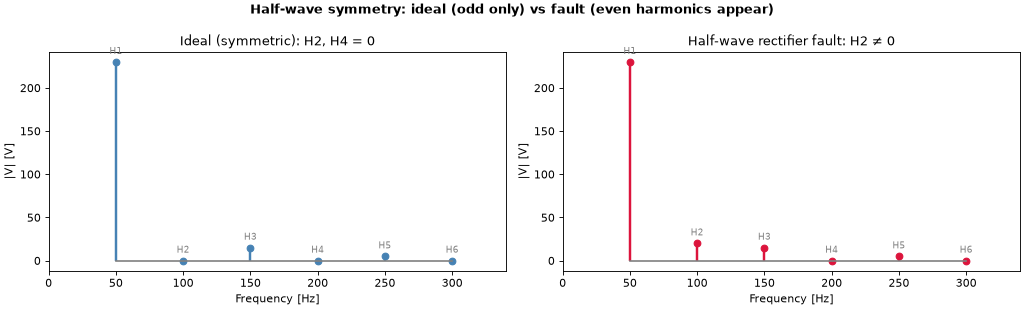

Ideal grid:  H1=230 V,  H2=0.0 V,  H3=15 V  (H2 ≈ 0 ✓)
Fault grid:  H1=230 V,  H2=20.0 V,  H3=15 V  (H2 ≠ 0 — rectifier fault)


In [3]:
from numpy.fft import rfft, rfftfreq

fs_demo = 1024.0
T_demo = 4.0
t_d = np.arange(int(T_demo * fs_demo)) / fs_demo
V1, V3, V5 = 230.0, 15.0, 5.0

# Ideal: half-wave symmetric (odd only)
v_odd = (V1 * np.cos(2 * np.pi * f0 * t_d) +
         V3 * np.cos(2 * np.pi * 3 * f0 * t_d + np.pi / 4) +
         V5 * np.cos(2 * np.pi * 5 * f0 * t_d + np.pi / 3))

# Faulty: half-wave rectifier adds H2 (2nd harmonic)
V2_fault = 20.0
v_fault = v_odd + V2_fault * np.cos(2 * np.pi * 2 * f0 * t_d + 0.8)

fft_norm = 2 / len(t_d)   # single-sided FFT amplitude normalization, reused below
harmonics_k = np.arange(1, 7)
harm_idx = (harmonics_k * f0 * T_demo).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("Half-wave symmetry: ideal (odd only) vs fault (even harmonics appear)", fontweight="bold")

# Plot amplitude only at the 6 harmonic bins (stem, not bar): with a 0-340 Hz axis a
# fractional-Hz-wide bar is sub-pixel and invisible for anything but the tallest peak.
signals = [v_odd, v_fault]
titles = ["Ideal (symmetric): H2, H4 = 0", "Half-wave rectifier fault: H2 ≠ 0"]
colors = ["steelblue", "crimson"]
for ax, v, title, col in zip(axes, signals, titles, colors):
    spec_full = np.abs(rfft(v)) * fft_norm
    amps = spec_full[harm_idx]
    markerline, stemlines, baseline = ax.stem(harmonics_k * f0, amps, basefmt="gray")
    plt.setp(stemlines, color=col, linewidth=2.2)
    plt.setp(markerline, color=col, markersize=6)
    for k, a in zip(harmonics_k, amps):
        ax.text(k * f0, a + amps.max() * 0.04, f"H{k}", ha="center", fontsize=8, color="gray")
    ax.set_xlim(0, 340)
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel("|V| [V]")
    ax.set_title(title)

plt.tight_layout()
plt.show()


# Single-sided FFT amplitude at a chosen harmonic of f0
def harmonic_amplitude(signal, harmonic_order):
    bin_idx = int(harmonic_order * f0 * T_demo)
    return np.abs(rfft(signal)[bin_idx]) * fft_norm


print("Ideal grid:  H1=%.0f V,  H2=%.1f V,  H3=%.0f V  (H2 ≈ 0 ✓)" % (
    harmonic_amplitude(v_odd, 1), harmonic_amplitude(v_odd, 2), harmonic_amplitude(v_odd, 3)))
print("Fault grid:  H1=%.0f V,  H2=%.1f V,  H3=%.0f V  (H2 ≠ 0 — rectifier fault)" % (
    harmonic_amplitude(v_fault, 1), harmonic_amplitude(v_fault, 2), harmonic_amplitude(v_fault, 3)))


---
## Step 3 — The Kalman Filter as a Phasor Meter

### Lab-Frame Formulation: No Demodulation

We want to track the phasor of each harmonic directly from the **raw measured
voltage**. This method needs no Hilbert transform and no lock-in demodulation.

This is the **lab-frame** approach. Compare it with notebook 02's rotating-frame
`OscillatorModel`, which demodulates the signal first.

**State.** The state stacks all phasors together, one pair per harmonic:
$$x = [\mathrm{Re}_1, \mathrm{Im}_1,\ \mathrm{Re}_2, \mathrm{Im}_2,\ \dots,\ \mathrm{Re}_N, \mathrm{Im}_N]^\top \quad (2N \text{ states})$$

**Dynamics.** The state evolves as $x_{k+1} = x_k + w_k$, with $F = I$. A steady
sinusoid has constant phasors, so the state transition is the identity. Process
noise $w_k$ (set by `process_uncertainty`) is small; it allows slow drift.

**Observation.** The measured voltage is a scalar. It equals the real part of the
rotating sum of all phasors. The carrier rotation appears in the **time-varying
observation map** $H(t)$, not in the state:
$$z(t) = v(t) = \sum_k \mathrm{Re}_k \cos(\omega_k t) - \mathrm{Im}_k \sin(\omega_k t)$$
$$H(t) = [\cos\omega_1 t,\ -\sin\omega_1 t,\ \cos\omega_2 t,\ -\sin\omega_2 t,\ \dots] \quad (1 \times 2N)$$

### Why Joint Estimation Prevents Leakage

All $N$ phasors must together explain the one measured voltage. The strong
fundamental H1 (230 V) is fully claimed by its own phasor. An absent harmonic, say
H2, is then forced to zero. No leftover signal remains for it to absorb.

A bank of independent per-harmonic demodulators cannot do this. In such a bank, the
230 V fundamental survives the H2 demodulation step. It appears as a rotating
phasor with constant magnitude. This produces a spurious amplitude of about 23 V,
even when the true H2 is zero.

### Lab Frame vs. Rotating Frame: Where the Carrier Sits

| | Lab frame (`PhasorOscillatorModel`) | Rotating frame (`OscillatorModel`, notebook 02) |
|---|---|---|
| Carrier lives in | `H(t)` (time-varying observation map) | `F = expm(Δω)` (state transition) |
| `F` | `I` | `expm(Δω·dt)` |
| `H` | `[cos ωt, −sin ωt]` (time-varying) | identity |
| Demodulation | none — the real signal goes in directly | Hilbert transform, then shift to baseband |
| Lines tracked | any set of frequencies, wide-band | one narrow window per mode |
| Best for | strong signals, wide-spread (mains) | weak signals, narrowband (violin modes) |


---
## Step 4 — `PhasorOscillatorModel`: A Generic Lab-Frame Tracker

The base class tracks **any set of frequencies**, not only harmonics. It works
directly on a **real signal**, with no demodulation step.

Give it two unrelated tones, and it recovers both.


n=4, m=1  (2 phasors → 4 states, 1 real channel — no demodulation)
Recovered amplitudes (steady-state, want 1.00, 0.50): [1.    0.501]


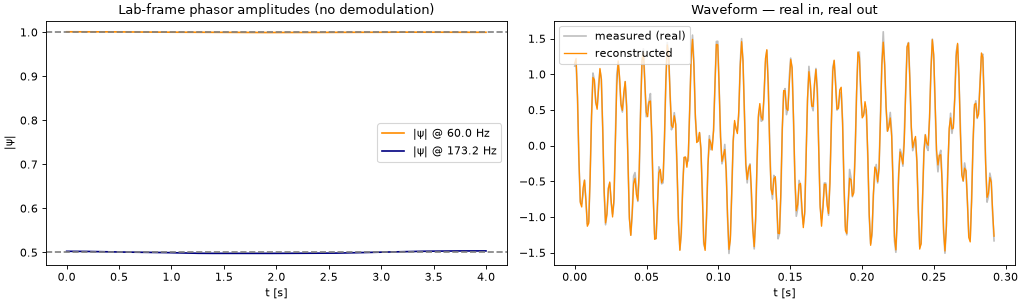

In [4]:
from kalman.apps.resonators.oscillators import PhasorOscillatorModel

fs_demo, T_demo = 1024.0, 4.0
t_demo = np.arange(int(T_demo * fs_demo)) / fs_demo
f_a, f_b = 60.0, 173.2
A_a, A_b = 1.0, 0.5
sig = (A_a * np.cos(2 * np.pi * f_a * t_demo + 0.4)
       + A_b * np.cos(2 * np.pi * f_b * t_demo - 1.1)
       + 0.05 * np.random.randn(len(t_demo)))

phasor = PhasorOscillatorModel("demo", [f_a, f_b], fs=fs_demo,
                               measurement_uncertainty=0.05,
                               process_uncertainty=1e-4, p0_std=10.0)
rec_p = phasor.filter(sig, smooth=True)
amp_p = phasor.amplitudes(rec_p)
recon_p = phasor.reconstruct(rec_p)

print(f"n={phasor.n}, m={phasor.m}  (2 phasors → 4 states, 1 real channel — no demodulation)")
steady_state_amp = amp_p[len(t_demo) // 2:].mean(axis=0)   # average over 2nd half, after convergence
print("Recovered amplitudes (steady-state, want %.2f, %.2f): %s" %
      (A_a, A_b, np.round(steady_state_amp, 3)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(t_demo, amp_p[:, 0], color="darkorange", label=f"|ψ| @ {f_a} Hz")
axes[0].plot(t_demo, amp_p[:, 1], color="navy", label=f"|ψ| @ {f_b} Hz")
axes[0].axhline(A_a, ls="--", color="gray")
axes[0].axhline(A_b, ls="--", color="gray")
axes[0].set_title("Lab-frame phasor amplitudes (no demodulation)")
axes[0].set_xlabel("t [s]")
axes[0].set_ylabel("|ψ|")
axes[0].legend()

n_preview = 300   # number of samples shown in the waveform preview
axes[1].plot(t_demo[:n_preview], sig[:n_preview], color="gray", alpha=0.5, label="measured (real)")
axes[1].plot(t_demo[:n_preview], recon_p[:n_preview], color="darkorange", lw=1.2, label="reconstructed")
axes[1].set_title("Waveform — real in, real out")
axes[1].set_xlabel("t [s]")
axes[1].legend()
plt.tight_layout()
plt.show()


---
## Step 5 — Build a Synthetic Power Grid Signal

We build a **controlled test signal** with known harmonic content:
- Fundamental: 50 Hz, 230 V
- 3rd harmonic: 150 Hz, 15 V
- 5th harmonic: 250 Hz, 5 V
- Gaussian noise: standard deviation σ = 10 V

The even harmonics H2 and H4 are deliberately absent. This models an ideal,
symmetric load.

We then track five harmonics with the filter. We expect H2 and H4 to settle near
zero.


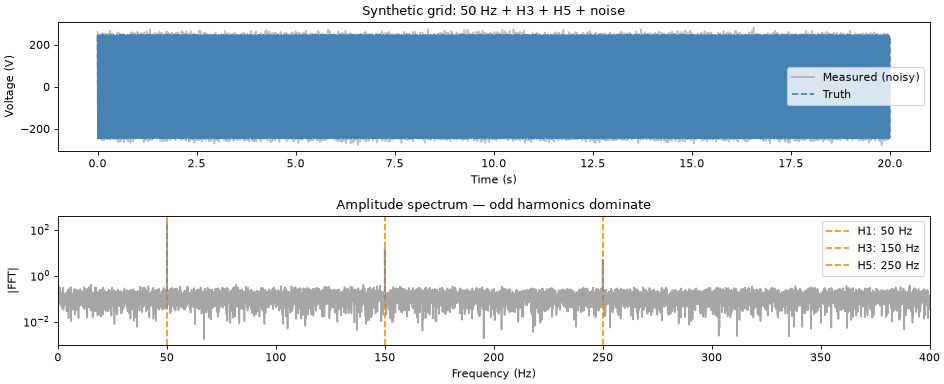

In [5]:
f0 = 50.0
fs = 1024.0
T = 20.0
t = np.arange(int(T * fs)) / fs

A1, phi1 = 230.0, 0.0
A3, phi3 = 15.0, np.pi / 4
A5, phi5 = 5.0, np.pi / 3

v_clean = (A1 * np.cos(2 * np.pi * f0 * t + phi1)
         + A3 * np.cos(2 * np.pi * 3 * f0 * t + phi3)
         + A5 * np.cos(2 * np.pi * 5 * f0 * t + phi5))
noise_std = 10.0
np.random.seed(0)
v_noisy = v_clean + np.random.normal(0, noise_std, len(t))

fig, axes = plt.subplots(2, 1, figsize=(12, 5))
axes[0].plot(t, v_noisy, alpha=0.5, color="gray", label="Measured (noisy)")
axes[0].plot(t, v_clean, "--", color="steelblue", label="Truth")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Voltage (V)")
axes[0].set_title("Synthetic grid: 50 Hz + H3 + H5 + noise")
axes[0].legend()

freqs_d = rfftfreq(len(t), 1 / fs)
spectrum = np.abs(rfft(v_noisy)) * 2 / len(t)
axes[1].semilogy(freqs_d, spectrum, color="gray", alpha=0.7)
harmonic_labels = [(50, "H1"), (150, "H3"), (250, "H5")]
for freq_hz, label in harmonic_labels:
    axes[1].axvline(freq_hz, ls="--", color="darkorange", lw=1.5, zorder=-1, label=f"{label}: {freq_hz} Hz")
axes[1].set_xlim(0, 400)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("|FFT|")
axes[1].set_title("Amplitude spectrum — odd harmonics dominate")
axes[1].legend()
plt.tight_layout()
plt.show()


---
## Step 6 — `PowerGridStateModel`: A Mains Specialization

`PowerGridStateModel` is a `PhasorOscillatorModel` with one restriction. Its
candidate frequencies are fixed to the harmonic ladder of a fundamental frequency
`f0`.

Everything else carries over from the base class: $F = I$, the time-varying
observation map $H(t)$, joint estimation, and no demodulation.

We track **five harmonics (H1 through H5)** at the same time. We seed H1, H3, and
H5 with reasonable initial values, and set H2 and H4 to zero.

The filter has two tasks:
- Converge H1 to 230 V, H3 to 15 V, and H5 to 5 V.
- Keep H2 and H4 near zero. Joint estimation prevents leakage between harmonics.


PowerGridStateModel(KalmanModel) @ fs=1024.0Hz
    Power Grid Harmonic Tracker (v4.0)
        Mains specialization of PhasorOscillatorModel:
        joint lab-frame phasor estimator tracking
        N harmonics of a 50/60 Hz grid from the
        scalar voltage — all harmonics coupled
        through one measurement, so absent (even)
        harmonics read ≈ 0.
    Dimensions Summary:
        State Vector....................................: 10 dims (PhasorState<REAL, IMAG>)
        Observation.....................................: 1 dim  (PowerGridObservable<VOLTAGE>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 10x1 dims
        State Covariance (P0)...........................: 10x10 dims



Chrono summary:
    #   label                         t          ΔT
  ───   ───────────────────   ─────────   ─────────
    1.  Model initialized        0.3 ms      0.3 ms
    2.  Filtering completed    812.6 ms    812.3 ms
  ───   ───────────────────   ─────────   ─────────
        total                  931.1 ms


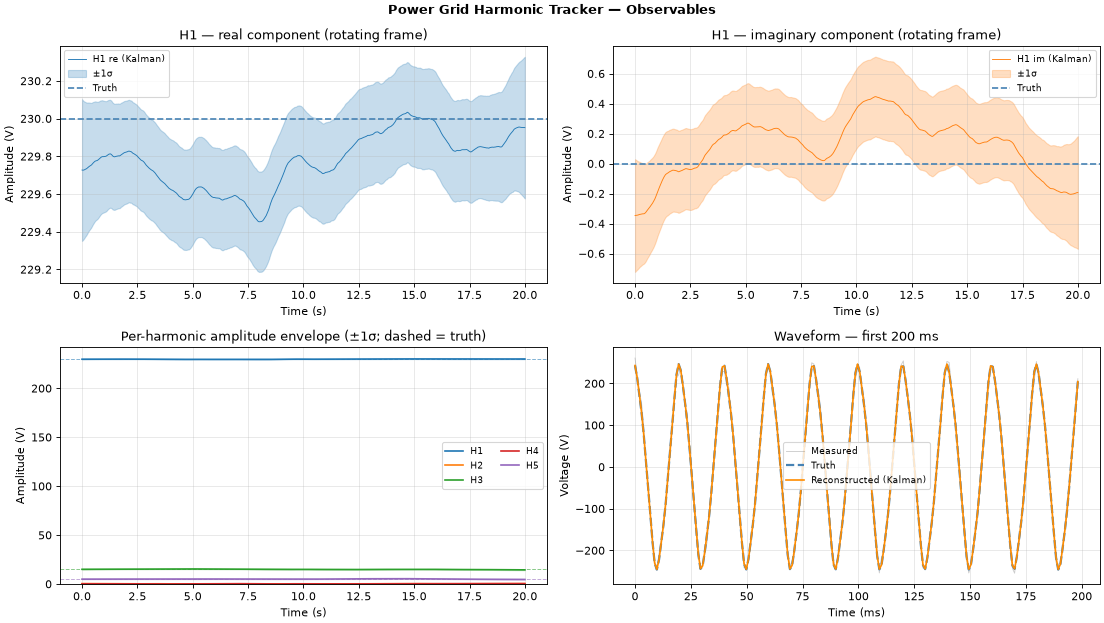

In [6]:
from kalman.apps.resonators.powergrids import PowerGridStateModel

chrono.restart()
grid = PowerGridStateModel("L1", f0=f0, harmonics=5, fs=fs,
                           measurement_uncertainty=noise_std,
                           process_uncertainty=0.01)
grid.initial_state([[A1, 0],   # H1
                    [0,  0],   # H2 (absent)
                    [A3, 0],   # H3
                    [0,  0],   # H4 (absent)
                    [A5, 0]])  # H5
grid.print()
chrono.lap("Model initialized")

record = grid.filter(v_noisy, smooth=True, reset=True)
chrono.lap("Filtering completed")

grid.plot(record, measured=v_noisy, truth=v_clean,
          true_amplitudes=[A1, 0, A3, 0, A5])

amplitudes, sigma_amp = grid.harmonic_envelope(record)
chrono.summary()

### Dynamic Waveform Replay

Slide a 200 ms window across the signal. Watch the Kalman reconstruction track the
measured voltage against the true voltage. The plot follows the filter from its
initial transient into steady state.


In [7]:
grid.plot(record, interactive=True, measured=v_noisy, truth=v_clean, window_ms=200)

---
## Step 6b — Harmonic Suppression: `subtract_voltage()`

Tracking each harmonic's phasor has more than diagnostic value. Once the filter
converges, it can remove the tracked harmonic content from the signal.

The function `subtract_voltage(measured, record)` computes
`measured − reconstruct_voltage(record)`. This removes all *tracked* harmonic
content, including the mains hum and distortion. Only the residual noise remains.

This is exactly what an **active harmonic filter** needs. It injects the
reconstructed waveform, with opposite sign, as a cancelling current.

The cell below compares two modes:
- **Causal filter** (`smooth=False`). This mode uses only past observations. The
  acquisition transient is visible in the first few cycles.
- **RTS smoother** (`smooth=True`). This mode uses all data, both past and future.
  Suppression is close to optimal over the full record. This is why the earlier
  plot looked almost perfect: the smoother is non-causal.

This function is the lab-frame counterpart to `InterferometerModel.subtract()` in
notebook 02.


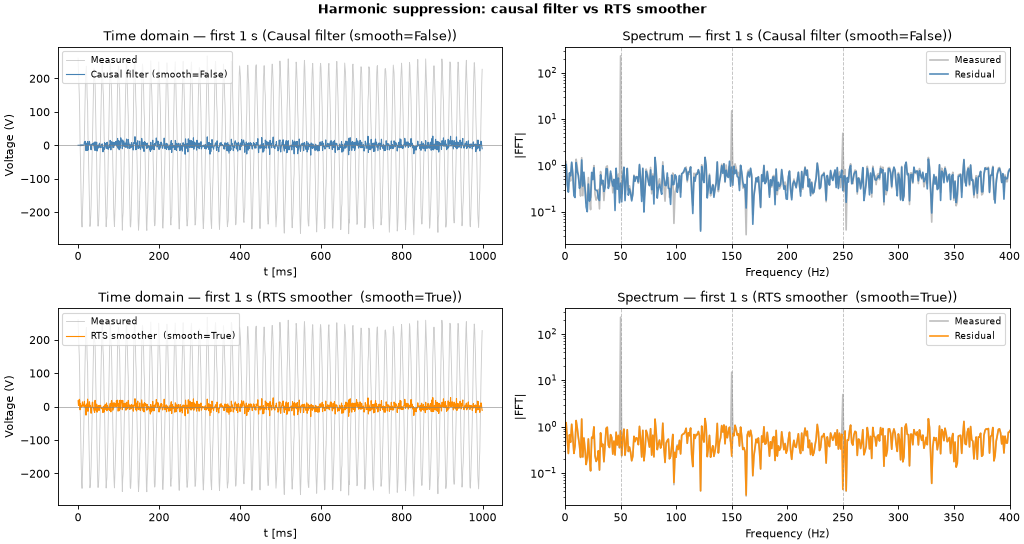

Causal   residual std (tail): 9.90 V
Smoother residual std (tail): 9.93 V  (noise σ = 10 V)


In [8]:
# Causal filter (forward-only, no future information)
record_causal = grid.filter(v_noisy, smooth=False, reset=True)

residual_smooth = grid.subtract_voltage(v_noisy, record)         # RTS smoother: non-causal
residual_causal = grid.subtract_voltage(v_noisy, record_causal)  # causal: online real-time

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
fig.suptitle("Harmonic suppression: causal filter vs RTS smoother", fontweight="bold")

n_show = int(fs)                              # first 1 s — covers the acquisition transient
freqs_w = rfftfreq(n_show, 1 / fs)            # frequency axis for the windowed spectrum

runs = [
    (residual_causal, "Causal filter (smooth=False)", "steelblue"),
    (residual_smooth, "RTS smoother  (smooth=True)",  "darkorange"),
]
for row, (res, label, color) in enumerate(runs):
    ax = axes[row, 0]
    ax.plot(t[:n_show] * 1e3, v_noisy[:n_show], color="gray", alpha=0.4, lw=0.8, label="Measured")
    ax.plot(t[:n_show] * 1e3, res[:n_show], color=color, lw=1.0, label=label)
    ax.axhline(0, color="gray", lw=0.5)
    ax.set_xlabel("t [ms]")
    ax.set_ylabel("Voltage (V)")
    ax.set_title(f"Time domain — first 1 s ({label})")
    ax.legend(fontsize=8)

    ax = axes[row, 1]
    spec_before = np.abs(rfft(v_noisy[:n_show])) * 2 / n_show   # same window as time domain
    spec_after = np.abs(rfft(res[:n_show])) * 2 / n_show
    ax.semilogy(freqs_w, spec_before, color="gray", alpha=0.5, label="Measured")
    ax.semilogy(freqs_w, spec_after, color=color, alpha=0.9, label="Residual")
    for freq_hz in [50, 150, 250]:
        ax.axvline(freq_hz, ls="--", color="gray", lw=0.8, alpha=0.5)
    ax.set_xlim(0, 400)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("|FFT|")
    ax.set_title(f"Spectrum — first 1 s ({label})")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

tail_slice = slice(-len(t) // 10, None)   # last 10% of the record, after convergence
print(f"Causal   residual std (tail): {np.std(residual_causal[tail_slice]):.2f} V")
print(f"Smoother residual std (tail): {np.std(residual_smooth[tail_slice]):.2f} V  (noise σ = {noise_std:.0f} V)")


---
## Step 7 — Total Harmonic Distortion (THD) With Uncertainty

$$\mathrm{THD} = \frac{\sqrt{A_2^2 + A_3^2 + \cdots + A_N^2}}{A_1} \times 100\%$$

The Kalman filter maintains a covariance matrix for the state. We can use it to
propagate the per-harmonic amplitude uncertainty $\sigma_{A_k}$, from $P_k$, into a
**±1σ confidence band on THD**. A plain FFT cannot provide this uncertainty band.


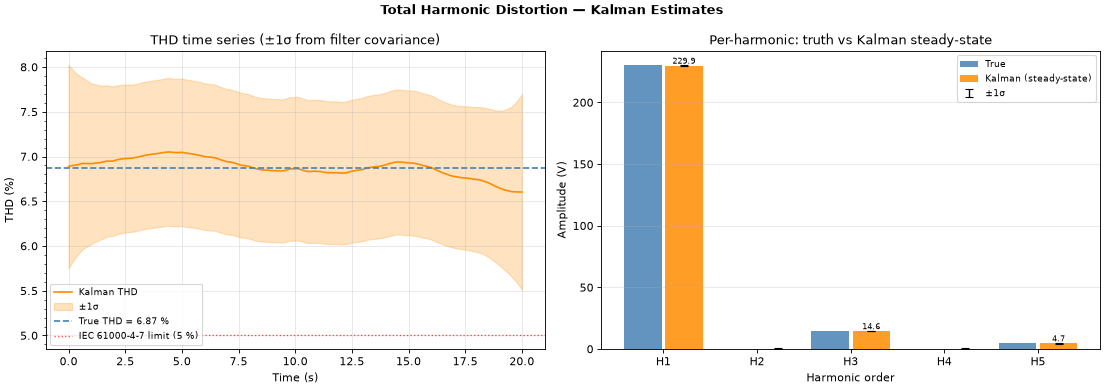

Steady-state THD: 6.660 %  (true: 6.875 %)


In [9]:
import matplotlib.ticker as mticker

N_harm = grid.n_harmonics
A1_est = amplitudes[:, 0]
distortion_mag = np.sqrt(np.sum(amplitudes[:, 1:]**2, axis=1))   # sqrt(sum of non-fundamental amplitudes^2)
thd = 100 * distortion_mag / (A1_est + 1e-12)

sigma_thd = np.zeros(len(t))
denom = (A1_est * distortion_mag + 1e-12)
for k in range(1, N_harm):
    sigma_thd += (amplitudes[:, k] / denom)**2 * sigma_amp[:, k]**2
sigma_thd += (thd / (A1_est + 1e-12))**2 * sigma_amp[:, 0]**2
sigma_thd = 100 * np.sqrt(sigma_thd)

thd_true = 100 * np.sqrt(A3**2 + A5**2) / A1
steady_state_slice = slice(-len(t) // 10, None)   # last 10% of the record, after convergence
steady_state_amps = amplitudes[steady_state_slice].mean(axis=0)
steady_state_thd = thd[steady_state_slice].mean()
true_amps = np.array([A1, 0, A3, 0, A5])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Total Harmonic Distortion — Kalman Estimates", fontweight="bold")

ax = axes[0]
ax.plot(t, thd, color="darkorange", lw=1.5, label="Kalman THD")
ax.fill_between(t, thd - sigma_thd, thd + sigma_thd, color="darkorange", alpha=0.25, label="±1σ")
ax.axhline(thd_true, ls="--", color="steelblue", lw=1.5, label=f"True THD = {thd_true:.2f} %")
ax.axhline(5.0, ls=":", color="red", lw=1.2, alpha=0.7, label="IEC 61000-4-7 limit (5 %)")
ax.set_xlabel("Time (s)")
ax.set_ylabel("THD (%)")
ax.set_title("THD time series (±1σ from filter covariance)")
ax.yaxis.set_minor_locator(mticker.AutoMinorLocator())
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

ax = axes[1]
x_pos = np.arange(1, N_harm + 1)
ax.bar(x_pos - 0.22, true_amps, 0.40, label="True", color="steelblue", alpha=0.85)
bars_est = ax.bar(x_pos + 0.22, steady_state_amps, 0.40, label="Kalman (steady-state)", color="darkorange", alpha=0.85)
ax.errorbar(x_pos + 0.22, steady_state_amps, yerr=sigma_amp[steady_state_slice].mean(axis=0),
            fmt="none", color="black", capsize=4, lw=1.2, label="±1σ")
for bar, val in zip(bars_est, steady_state_amps):
    if val > 1:
        ax.text(bar.get_x() + bar.get_width() / 2, val + 1.5, f"{val:.1f}", ha="center", fontsize=7.5)
ax.set_xlabel("Harmonic order")
ax.set_ylabel("Amplitude (V)")
ax.set_title("Per-harmonic: truth vs Kalman steady-state")
ax.set_xticks(x_pos)
ax.set_xticklabels([f"H{k}" for k in range(1, N_harm + 1)])
ax.grid(True, axis="y", alpha=0.3)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()
print(f"Steady-state THD: {steady_state_thd:.3f} %  (true: {thd_true:.3f} %)")


---
## Step 8 — Fault Diagnosis: A Half-Wave Rectifier Load

A half-wave rectifier clips one half-cycle of the supply current. This breaks
half-wave symmetry and injects **even harmonics** (H2, H4, and so on).

The `PowerGridStateModel` detects this fault immediately. H2 rises from zero when
the fault starts, at t = 2.5 s.

This shows the **diagnostic value** of joint phasor estimation, compared to a bank
of independent demodulators. The H2 channel correctly starts at zero, even with the
strong 230 V fundamental present. It rises only when genuine H2 content appears.


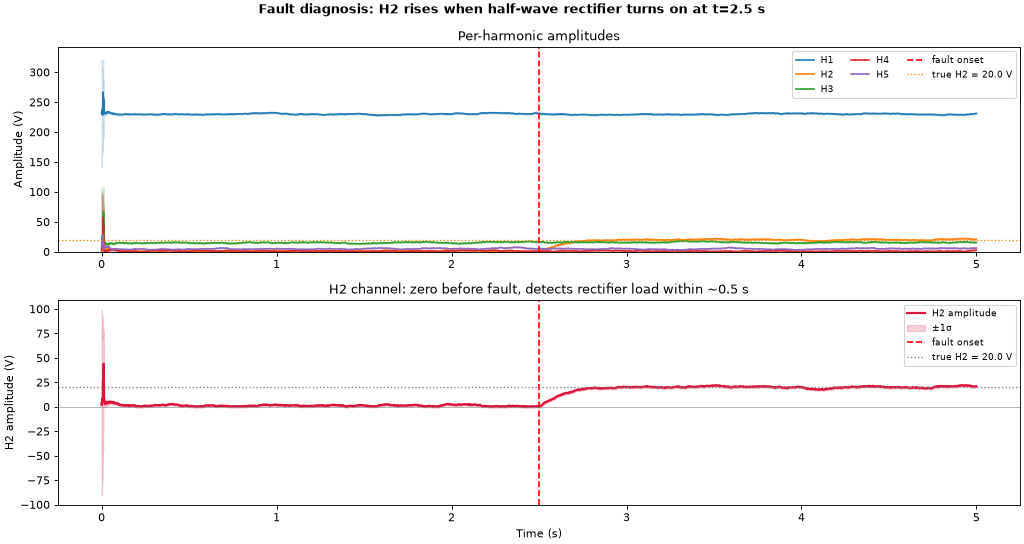

H2 crosses 10 V threshold at t = 2.596 s (detection latency: 0.096 s)


In [10]:
T_fault = 5.0
t_f = np.arange(int(T_fault * fs)) / fs
fault_onset = 2.5   # seconds: half-wave rectifier turns on
V2_fault = 20.0     # 2nd harmonic injected by the rectifier [V]

np.random.seed(7)
v_fault = (A1 * np.cos(2 * np.pi * f0 * t_f) +
           A3 * np.cos(2 * np.pi * 3 * f0 * t_f + phi3) +
           A5 * np.cos(2 * np.pi * 5 * f0 * t_f + phi5) +
           np.random.normal(0, noise_std, len(t_f)))
# Inject H2 after fault_onset
idx_on = int(fault_onset * fs)
v_fault[idx_on:] += V2_fault * np.cos(2 * np.pi * 2 * f0 * t_f[idx_on:])

grid_f = PowerGridStateModel("L1_fault", f0=f0, harmonics=5, fs=fs,
                              measurement_uncertainty=noise_std,
                              process_uncertainty=0.1)   # faster adaptation
grid_f.initial_state([[A1, 0], [0, 0], [A3, 0], [0, 0], [A5, 0]])
rec_f = grid_f.filter(v_fault, smooth=False, reset=True)   # causal (no smoother) to see detection speed

amp_f, sig_f = grid_f.harmonic_envelope(rec_f)

fig, axes = plt.subplots(2, 1, figsize=(13, 7))
fig.suptitle("Fault diagnosis: H2 rises when half-wave rectifier turns on at t=2.5 s", fontweight="bold")

colors_h = plt.cm.tab10(np.arange(5) % 10)
for k in range(5):
    axes[0].plot(t_f, amp_f[:, k], color=colors_h[k], lw=1.5, label=f"H{k + 1}")
    axes[0].fill_between(t_f, amp_f[:, k] - sig_f[:, k], amp_f[:, k] + sig_f[:, k],
                         color=colors_h[k], alpha=0.18)
axes[0].axvline(fault_onset, ls="--", color="red", lw=1.5, label="fault onset")
axes[0].axhline(V2_fault, ls=":", color="darkorange", lw=1.2, label=f"true H2 = {V2_fault} V")
axes[0].set_ylabel("Amplitude (V)")
axes[0].set_title("Per-harmonic amplitudes")
axes[0].legend(fontsize=8, ncol=3)
axes[0].set_ylim(bottom=0)

# Focus on H2 only
axes[1].plot(t_f, amp_f[:, 1], color="crimson", lw=2, label="H2 amplitude")
axes[1].fill_between(t_f, amp_f[:, 1] - sig_f[:, 1], amp_f[:, 1] + sig_f[:, 1],
                     color="crimson", alpha=0.2, label="±1σ")
axes[1].axvline(fault_onset, ls="--", color="red", lw=1.5, label="fault onset")
axes[1].axhline(0, color="gray", lw=0.5)
axes[1].axhline(V2_fault, ls=":", color="gray", lw=1.2, label=f"true H2 = {V2_fault} V")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("H2 amplitude (V)")
axes[1].set_title("H2 channel: zero before fault, detects rectifier load within ~0.5 s")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Detection latency
threshold = V2_fault * 0.5
detect_idx = np.where((t_f > fault_onset) & (amp_f[:, 1] > threshold))[0]
if detect_idx.size:
    print(f"H2 crosses {threshold:.0f} V threshold at t = {t_f[detect_idx[0]]:.3f} s "
          f"(detection latency: {t_f[detect_idx[0]] - fault_onset:.3f} s)")
else:
    print("H2 did not cross threshold in this run — try increasing process_uncertainty.")


---
## Possible Extensions

### 1. Voltage and Current: Complex Power per Harmonic
Add a second `PowerGridStateModel` for the current. Then compute, per harmonic,
from the Kalman estimates:
- Active power: $P_k = \tfrac{1}{2}\mathrm{Re}[V_k I_k^*]$
- Reactive power: $Q_k = \tfrac{1}{2}\mathrm{Im}[V_k I_k^*]$

### 2. Fundamental Frequency Tracking
Add a frequency offset $\delta f$ to the state, modeled as a random walk. Update
all $\omega_k$ dynamically. This gives a **frequency-adaptive** harmonic tracker
for weak grids.

### 3. Inter-Harmonics
Arc furnaces and cycloconverters inject frequencies that are not integer multiples
of $f_0$, for example 75 Hz. Add `PhasorOscillatorModel` entries at these
non-integer frequencies, alongside the harmonic bank.

### 4. Real-Time Streaming
The `filter()` method processes one batch of data. For causal, real-time
streaming, call the predict and update steps directly:
```python
for z_t in voltage_stream:
    kf._predict(kf.x, kf.P, u=None, t=t)
    kf._update(z_t, t=t)
    h1_amp = np.hypot(kf.x[0], kf.x[1])   # H1 amplitude in real time
    t += 1 / fs
```
This gives sub-cycle latency. DFT-based methods need a full window, so they are
far slower.
